<div dir="rtl" lang="he" xml:lang="he">
<font size=6> עיבוד נתונים - מעבדה ג'</font>

<font size=5> מחברת colab </font>

---'` comment #` .

---
<h1>
<font size=5><b>1. ייבוא חבילות</b></font>
</h1>

---







--- Fit Results for /content/TEM20.jpg ---
Beam center (x0): 340.10 pixels
Beam waist (w):   229.35 pixels
Goodness of fit (R^2): 0.3776

A_0 = 0.5913 (Relative contribution: 87.5%)
A_1 = 0.0000 (Relative contribution: 0.0%)
A_2 = 0.0768 (Relative contribution: 11.4%)
A_3 = 0.0079 (Relative contribution: 1.2%)


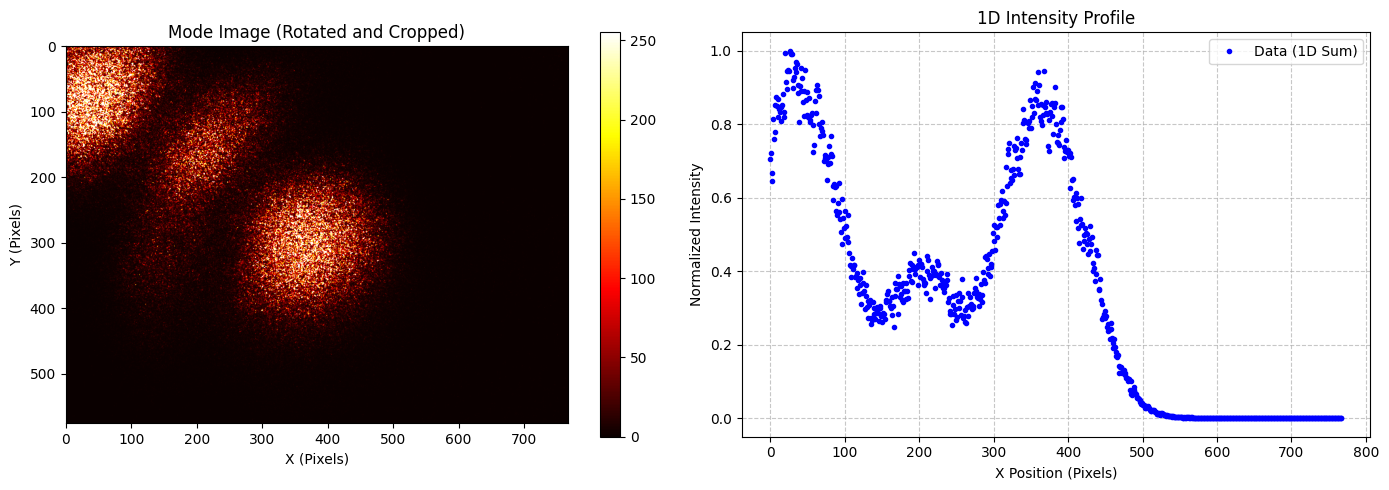

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Load image and convert to grayscale
img_path = '/content/TEM20.jpg'
img_raw = cv2.imread(img_path)

if img_raw is not None:
    img = cv2.cvtColor(img_raw, cv2.COLOR_BGR2GRAY)
else:
    # If the file is not loaded, create a synthetic demo image
    print("Warning: Image file not found. Creating a synthetic image.")
    x_grid, y_grid = np.meshgrid(np.linspace(-10, 10, 500), np.linspace(-10, 10, 500))
    img = np.exp(-(x_grid**2 + y_grid**2) / 10) * 255
    img = img.astype(np.uint8)

# 2. Rotate image (if needed)
# Set rotation angle (in degrees)
angle = 0  # Change this value if the image needs rotation
if angle != 0:
    (h, w) = img.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    img_rot = cv2.warpAffine(img, M, (w, h))
else:
    img_rot = img.copy()

# 3. Define Region of Interest (ROI) manually in pixels instead of interactive imcrop
# Crop the center of the image by default
h, w = img_rot.shape
crop_ymin, crop_ymax = int(h * 0.2), int(h * 0.8)
crop_xmin, crop_xmax = int(w * 0.2), int(w * 0.8)
img_crop = img_rot[crop_ymin:crop_ymax, crop_xmin:crop_xmax]

# 4. Sum to 1D (noise reduction)
I_1D = np.sum(img_crop, axis=0).astype(float)

# Background subtraction and normalization
I_1D = I_1D - np.min(I_1D)
if np.max(I_1D) > 0:
    I_1D = I_1D / np.max(I_1D)

x = np.arange(len(I_1D))

# 5. Define Hermite-Gauss model
def hg_model(x, A0, A1, A2, A3, x0, w_param, offset):
    arg = np.sqrt(2) * (x - x0) / w_param
    # Hermite polynomials
    H0 = 1.0
    H1 = 2.0 * arg
    H2 = 4.0 * (arg**2) - 2.0
    H3 = 8.0 * (arg**3) - 12.0 * arg

    envelope = np.exp(-2.0 * (x - x0)**2 / (w_param**2))
    term = (A0 * H0**2 + A1 * H1**2 + A2 * H2**2 + A3 * H3**2) * envelope + offset
    return term

# Initial guesses
x0_guess = float(np.mean(x))
w_guess = float(len(x) / 4.0)
p0 = [0.5, 0.5, 0.1, 0.1, x0_guess, w_guess, 0.0]

# Parameter bounds
lb = [0, 0, 0, 0, float(np.min(x)), 1.0, -0.2]
ub = [10.0, 10.0, 10.0, 10.0, float(np.max(x)), float(len(x)), 0.5]

try:
    # Perform fit using curve_fit
    p_fit, pcov = curve_fit(hg_model, x, I_1D, p0=p0, bounds=(lb, ub))

    # Calculate R^2
    residuals = I_1D - hg_model(x, *p_fit)
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((I_1D - np.mean(I_1D))**2)
    R_squared = 1.0 - (ss_res / ss_tot)

    # Display results
    A_coeffs = p_fit[0:4]
    A_norm = A_coeffs / np.sum(A_coeffs) if np.sum(A_coeffs) > 0 else A_coeffs

    print(f"\n--- Fit Results for {img_path} ---")
    print(f"Beam center (x0): {p_fit[4]:.2f} pixels")
    print(f"Beam waist (w):   {p_fit[5]:.2f} pixels")
    print(f"Goodness of fit (R^2): {R_squared:.4f}\n")
    for i in range(4):
        print(f"A_{i} = {A_coeffs[i]:.4f} (Relative contribution: {A_norm[i]*100:.1f}%)")

    # 6. Plot graphs
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: Cropped mode image
    im = axes[0].imshow(img_crop, cmap='hot')
    fig.colorbar(im, ax=axes[0])
    axes[0].set_title('Mode Image (Rotated and Cropped)')
    axes[0].set_xlabel('X (Pixels)')
    axes[0].set_ylabel('Y (Pixels)')

    # Plot 2: Data points only
    axes[1].plot(x, I_1D, 'b.', label='Data (1D Sum)')
    axes[1].grid(True, linestyle='--', alpha=0.7)
    axes[1].set_title('1D Intensity Profile')
    axes[1].set_xlabel('X Position (Pixels)')
    axes[1].set_ylabel('Normalized Intensity')
    axes[1].legend()

    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Error during fitting: {e}")